# NeurWIN on EV charging: Algorithm 1's inputs → output θ⁺ → how θ⁺ is used

Each charging spot is an **arm** with state $s = (D, B)$: $D$ = rounds until the vehicle leaves, $B$ = charge it still needs. Activating an arm charges one unit (reward $1 - c = 0.5$); a vehicle that leaves with $B$ units missing costs $F(B) = 0.2B^2$.

**Algorithm 1** takes a few **inputs** (initial $\theta$, $\beta$, $L$, $m$, $R$), plays mini-batches of episodes on one arm in $\text{Env}^*(\lambda)$, and returns its **output** $\theta^+$: the weights of a network $f_{\theta^+}(D, B)$ meant to be the arm's Whittle index. The station then **uses** it: every round, score all $N$ arms with $f_{\theta^+}$ and activate the $M$ highest.

The sections follow that path: (1) inputs, (2) output θ⁺ compared with the closed-form index $W(D, B)$, (3) θ⁺ in use, (4) change an input and see the output change, (5) other station sizes. The line-by-line version of Algorithm 1 is in `algorithm1_walkthrough.ipynb`.

**How to use:** change the settings cell, then *Run All*. In VS Code, pick the repo's `.venv` as the kernel.

## Settings

Every cell below reads this cell and starts its output with `Settings used:`.

- **Algorithm 1 inputs** decide θ⁺. With the replication's values (below) θ⁺ is the authors' saved checkpoints, which `algorithm1.train()` reproduces exactly. Other values train a new θ⁺ once (about 2 minutes for 2,000 episodes) into `trainResults/experiments/` and reuse it after that.
- **Test settings** decide how θ⁺ is used and measured.
- **Section 4** trains, or reuses, one more θ⁺ with some inputs changed.

In [1]:
# Algorithm 1 inputs (the replication's values)
EPISODES = 2000    # episodes of training; mini-batches = EPISODES / R
m = 1              # sensitivity m of sigma_m in Env*(lam); the paper uses 1 for this arm
L = 1e-3           # learning rate L (Adam's step size; L_b = L in every mini-batch)
R = 5              # mini-batch size: episodes per gradient-ascent step
beta = 0.99        # discount factor beta in the discounted net reward G_e
seed = 50          # seed for the initial theta, s0, the vehicle arrivals and the action draws

# Test settings: how theta+ is used
N = 4              # number of arms (charging spots)
M = 1              # arms activated per round (1 <= M <= N)
RUNS = 50          # test episodes per point (the paper uses 50)
STRIDE = 50        # test every STRIDE-th saved checkpoint: 0, STRIDE, 2*STRIDE, ..., EPISODES

# Section 4: change an input
EXP_NAME = "m5"            # folder trainResults/experiments/<EXP_NAME>/ (never overwritten)
EXP_CHANGES = {"m": 5}     # Algorithm 1 inputs that differ from the ones above
# Section 5: other station sizes
SIZES = [(4, 1), (8, 2), (20, 5)]   # (N, M) pairs; the current (N, M) is always added


def settings_used(*groups):
    # print the settings a cell ran with: "inputs", "test", "exp", "sizes"
    parts = []
    if "inputs" in groups:
        parts.append(f"EPISODES={EPISODES}, m={m}, L={L}, R={R}, beta={beta}, seed={seed}")
    if "test" in groups:
        parts.append(f"N={N}, M={M}, RUNS={RUNS}, STRIDE={STRIDE}")
    if "exp" in groups:
        parts.append(f"EXP_NAME={EXP_NAME!r}, EXP_CHANGES={EXP_CHANGES}")
    if "sizes" in groups:
        parts.append(f"SIZES={sorted(set(SIZES) | {(N, M)})}")
    print("Settings used: " + ("; ".join(parts) or "none (this cell only loads code)"))


settings_used("inputs", "test", "exp", "sizes")

Settings used: EPISODES=2000, m=1, L=0.001, R=5, beta=0.99, seed=50; N=4, M=1, RUNS=50, STRIDE=50; EXP_NAME='m5', EXP_CHANGES={'m': 5}; SIZES=[(4, 1), (8, 2), (20, 5)]


## Load the helper functions

`explore_lib.py` (next to this notebook) runs Algorithm 1 through `algorithm1.py` and tests θ⁺ with the authors' environment and test loop, without changing any of the authors' files.

In [2]:
import sys
from pathlib import Path

for folder in (Path.cwd(), Path.cwd() / "replication", Path.cwd() / "NeurWIN" / "replication"):
    if (folder / "explore_lib.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("explore_lib.py not found: open this notebook from NeurWIN/replication")

import explore_lib as lab
settings_used()
print("NeurWIN folder:", lab.REPO)

Settings used: none (this cell only loads code)
NeurWIN folder: /Users/aidenlee/orca/Restless-Bandit/NeurWIN


## 1. Inputs of Algorithm 1

| input | meaning for one charging spot |
|---|---|
| initial θ | the network's starting weights, drawn from `seed` (`fcnn`, 2 → 16 → 32 → 1) |
| $\beta$ | how much a reward $t$ rounds later counts ($\beta^t$) in the discounted net reward $G_e$ |
| $L$ | learning rate $L_b$ of each gradient-ascent step |
| $m$ | sensitivity of $\sigma_m$: how sharply $\text{Env}^*(\lambda)$ approximates the step function of $\text{Env}(\lambda)$ |
| $R$ | episodes per mini-batch; the baseline $\bar G_b$ is their average |

Each mini-batch draws an activation cost $\lambda = f_\theta(s_0)$, plays $R$ episodes of 300 rounds, and moves θ toward the episodes with a positive offset net reward $G_e - \bar G_b$. The cell finds θ⁺ for these inputs.

In [3]:
settings_used("inputs")

inputs = dict(episodes=EPISODES, m=m, L=L, R=R, beta=beta, seed=seed)
main_dir = lab.theta_plus_dir(**inputs)
print(f"mini-batches: {EPISODES // R} of R = {R} episodes")
if main_dir == lab.DEFAULT_MODEL_DIR:
    print("These are the replication's inputs: theta+ is the authors' checkpoints in trainResults/neurwin/deadline_env/")
    print("(algorithm1.train() with these inputs reproduces them exactly: max difference 0).")
else:
    print("theta+ for these inputs is in", main_dir)

Settings used: EPISODES=2000, m=1, L=0.001, R=5, beta=0.99, seed=50
mini-batches: 400 of R = 5 episodes
These are the replication's inputs: theta+ is the authors' checkpoints in trainResults/neurwin/deadline_env/
(algorithm1.train() with these inputs reproduces them exactly: max difference 0).


## 2. Output θ⁺: how Whittle-accurate is $f_{\theta^+}$?

Left: the learned $f_{\theta^+}(D, B)$; right: the closed-form Whittle index $W(D, B)$, for the 120 states $D = 1..12$, $B = 0..9$. By Def. 4, $f_\theta$ is **Whittle-accurate** if, for every activation cost $\lambda$, activating in $\text{Env}(\lambda)$ is optimal exactly when $f_\theta(s) > \lambda$, i.e. exactly where $W(s) > \lambda$. So only the *order* of the scores matters, not their size: the table reports the rank correlation with $W$ and the share of state pairs that $f_{\theta^+}$ orders the same way as $W$ (100% would be Whittle-accurate on these states).

Settings used: EPISODES=2000, m=1, L=0.001, R=5, beta=0.99, seed=50


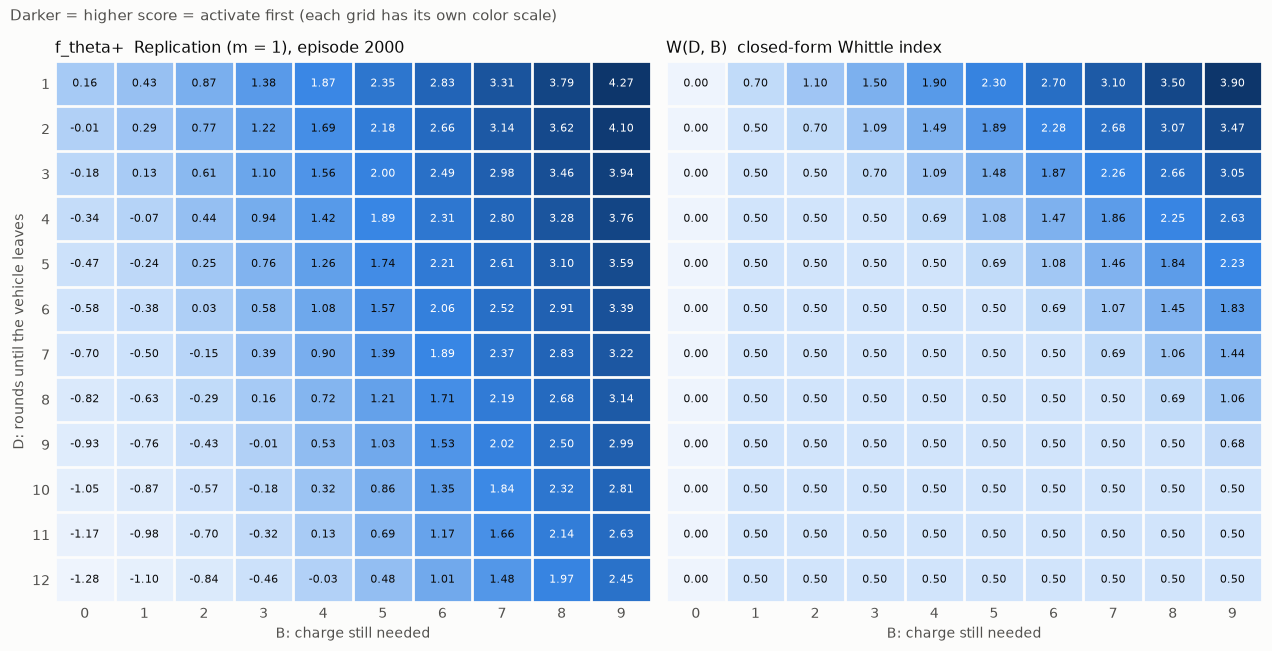

How Whittle-accurate theta+ is (Def. 4), over the 120 states D = 1..12, B = 0..9:
              model  episode  rank correlation with W pairs ordered like W
Replication (m = 1)     2000                    0.785                87.4%


In [4]:
settings_used("inputs")

lab.plot_theta_plus([main_dir])

## 3. How θ⁺ is used: score every arm, activate the top M

With $N$ arms and room to activate $M$ per round, the station scores each arm's state with $f_{\theta^+}(D, B)$ and activates the $M$ highest (ties go to the lowest arm number, as in the authors' test script). The closed-form index $W$ is used the same way on the same vehicle arrivals.

The chart repeats this with θ saved at different points of training: the solid line is the mean total discounted reward over `RUNS` test episodes, the band covers the middle 90%, and the dashed line is the closed-form index. With the default settings the last point is **−99.3** and the index **−105.1**.

Settings used: EPISODES=2000, m=1, L=0.001, R=5, beta=0.99, seed=50; N=4, M=1, RUNS=50, STRIDE=50


tested 41 checkpoints (episodes 0 to 2000) and the index: N=4, M=1, 50 runs each, 20 s


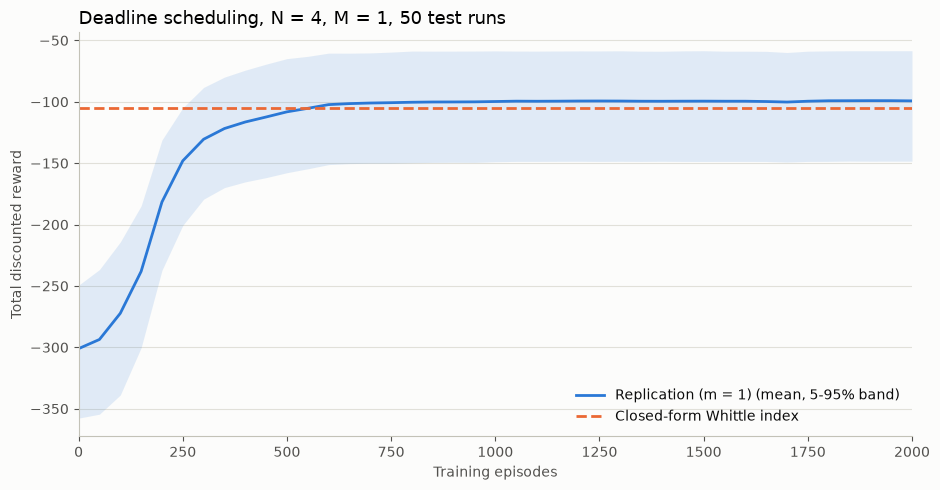

         experiment  N  M  last episode  NeurWIN   index  NeurWIN - index  std. error NeurWIN better in  first tested episode >= index
Replication (m = 1)  4  1          2000   -99.25 -105.05              5.8        0.35             50/50                            600


In [5]:
settings_used("inputs", "test")

main_result = lab.evaluate(main_dir, N=N, M=M, runs=RUNS, stride=STRIDE)
main_result.attrs["stride"] = STRIDE
lab.plot_curve([main_result], [lab.describe(main_dir)])

## 4. Change an input, see the output

Algorithm 1 is run again with the inputs above except for `EXP_CHANGES` (default: sensitivity $m = 5$ instead of 1), saved in `trainResults/experiments/<EXP_NAME>/`. A saved experiment is reused only if its inputs match, and is never overwritten (a different name is needed). Both θ⁺ are then compared: as an output (heatmaps, Whittle-accuracy) and in use (reward curves).

Settings used: EPISODES=2000, m=1, L=0.001, R=5, beta=0.99, seed=50; N=4, M=1, RUNS=50, STRIDE=50; EXP_NAME='m5', EXP_CHANGES={'m': 5}
'm5' was already trained with these inputs; reusing /Users/aidenlee/orca/Restless-Bandit/NeurWIN/trainResults/experiments/m5/


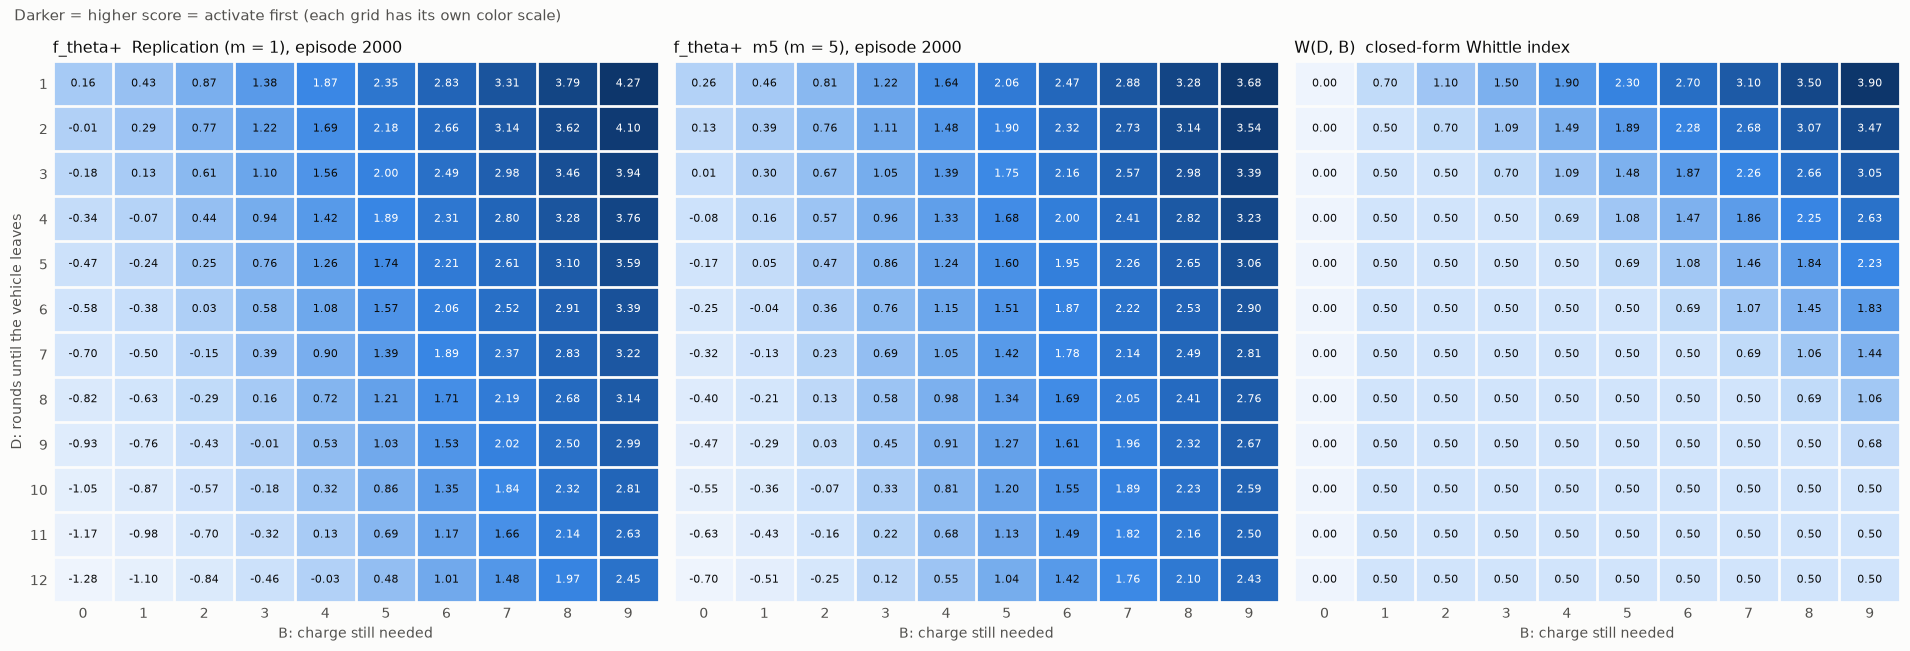

How Whittle-accurate theta+ is (Def. 4), over the 120 states D = 1..12, B = 0..9:
              model  episode  rank correlation with W pairs ordered like W
Replication (m = 1)     2000                    0.785                87.4%
         m5 (m = 5)     2000                    0.755                85.9%


tested 41 checkpoints (episodes 0 to 2000) and the index: N=4, M=1, 50 runs each, 21 s


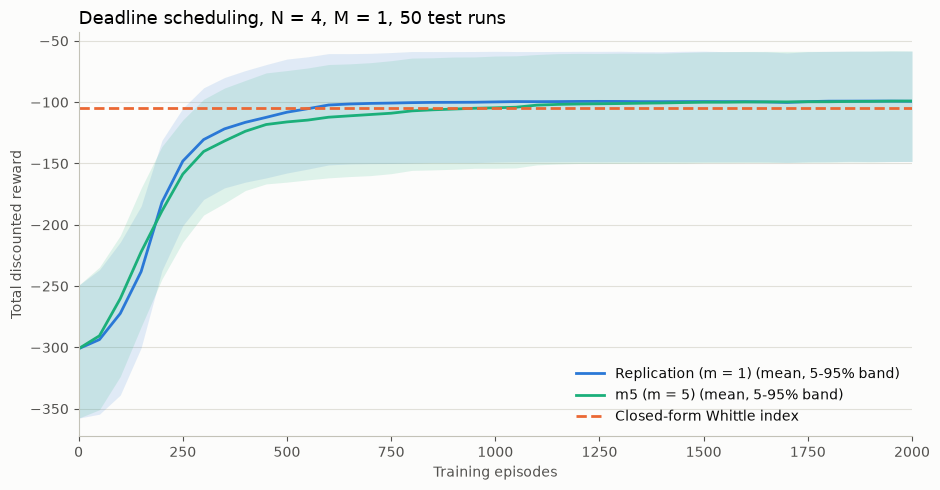

         experiment  N  M  last episode  NeurWIN   index  NeurWIN - index  std. error NeurWIN better in  first tested episode >= index
Replication (m = 1)  4  1          2000   -99.25 -105.05             5.80        0.35             50/50                            600
         m5 (m = 5)  4  1          2000   -99.08 -105.05             5.97        0.36             50/50                            950


In [6]:
settings_used("inputs", "test", "exp")

unknown = set(EXP_CHANGES) - set(inputs)
if unknown:
    raise ValueError(f"EXP_CHANGES can only change {sorted(inputs)}; got {sorted(unknown)}")
exp_dir = lab.train(EXP_NAME, **{**inputs, **EXP_CHANGES})

lab.plot_theta_plus([main_dir, exp_dir])

# reuse the section 3 result only if it was made with the current settings
if (main_result.attrs.get("model_dir"), main_result.attrs.get("N"), main_result.attrs.get("M"),
        main_result.attrs.get("runs"), main_result.attrs.get("stride")) != (str(main_dir), N, M, RUNS, STRIDE):
    main_result = lab.evaluate(main_dir, N=N, M=M, runs=RUNS, stride=STRIDE)
    main_result.attrs["stride"] = STRIDE
exp_result = lab.evaluate(exp_dir, N=N, M=M, runs=RUNS, stride=STRIDE)
lab.plot_curve([main_result, exp_result], [lab.describe(main_dir), lab.describe(exp_dir)])

## 5. Scaling with N and M

The same θ⁺ (from section 1) is used for larger stations, keeping the ratio of arms to activations. Each bar is the reward of "activate the top M by $f_{\theta^+}$" minus that of the closed-form index, as a percentage of the index; above zero means θ⁺ did better.

Settings used: EPISODES=2000, m=1, L=0.001, R=5, beta=0.99, seed=50; SIZES=[(4, 1), (8, 2), (20, 5)]


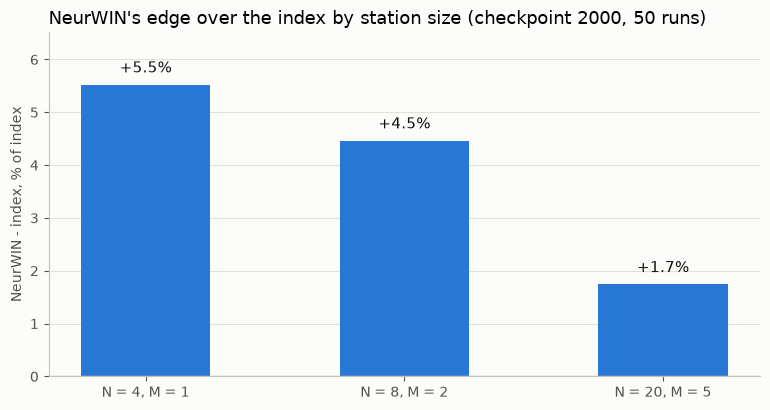

 N  M  NeurWIN   index  NeurWIN - index  % of index  std. error NeurWIN better in
 4  1   -99.25 -105.05             5.80        5.52        0.35             50/50
 8  2  -185.75 -194.41             8.67        4.46        0.50             50/50
20  5  -451.57 -459.56             7.98        1.74        0.55             49/50


In [7]:
sizes = sorted(set(SIZES) | {(N, M)})
settings_used("inputs", "sizes")

lab.plot_scaling(main_dir, sizes=sizes, runs=RUNS)